In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Cài các thư viện cần cho fine-tune BARTpho summarization.
!pip install transformers datasets rouge-score accelerate sentencepiece underthesea -q


Mounted at /content/drive
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 79.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 81.7 MB/s eta 0:00:00


In [2]:
import json
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast
from transformers import (
    MBartForConditionalGeneration,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)
from rouge_score import rouge_scorer
from underthesea import word_tokenize

BƯỚC 2: CẤU HÌNH

In [3]:
DATA_DIR = "/content/drive/MyDrive/BartPhoModel(24)"
TRAIN_PATH = os.path.join(DATA_DIR, "train.jsonl")
VALID_PATH = os.path.join(DATA_DIR, "valid.jsonl")
OUTPUT_DIR = os.path.join(DATA_DIR, "bartpho-manual-model")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Hyperparameters
MAX_ARTICLE_LEN = 512
MAX_SUMMARY_LEN = 160
BATCH_SIZE = 4
GRADIENT_ACCUMULATION = 2
LEARNING_RATE = 1e-5
NUM_EPOCHS = 15
WARMUP_RATIO = 0.2
MAX_GRAD_NORM = 1.0
NUM_BEAMS = 4

# ReduceLROnPlateau: tự giảm LR khi eval_loss không cải thiện
LR_REDUCE_FACTOR = 0.5    # Giảm LR còn 50%
LR_PATIENCE = 1           # Sau 1 epoch không cải thiện thì giảm
MIN_LR = 1e-6             # LR tối thiểu

# Early Stopping: dừng train khi eval_loss không cải thiện
EARLY_STOPPING_PATIENCE = 3  # Dừng sau 3 epoch không cải thiện

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


 BƯỚC 3: ĐỌC VÀ LỌC DỮ LIỆU

In [4]:
def load_jsonl(file_path):
    data = []
    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                item = json.loads(line.strip())
                data.append({
                    "article": item["article"],
                    "summary": item["chosen"]
                })
    print(f"Đọc {len(data)} mẫu từ {file_path}")
    return data

def word_segment(text):
    #return " ".join(word_tokenize(text))
    return word_tokenize(text, format="text")

def soft_filter(data, min_article_words=80, min_summary_words=20):
    """Lọc mềm: bỏ mẫu quá ngắn, giữ lại nhiều dữ liệu nhất."""
    filtered = []
    for item in data:
        if len(item["article"].split()) >= min_article_words and \
           len(item["summary"].split()) >= min_summary_words:
            filtered.append(item)
    print(f"  Lọc mềm: {len(data)} → {len(filtered)} mẫu")
    return filtered

def preprocess_data(data):
    """Word segmentation 1 LẦN DUY NHẤT trước khi train (không lặp mỗi epoch)."""
    processed = []
    for i, item in enumerate(data):
        if (i + 1) % 500 == 0:
            print(f"  Word segment: {i+1}/{len(data)}")
        processed.append({
            "article": word_segment(item["article"]),
            "summary": word_segment(item["summary"]),
        })
    print(f"  Xong: {len(processed)} mẫu đã segment")
    return processed

# Đọc → Lọc → Word segment (1 lần duy nhất)
train_data = soft_filter(load_jsonl(TRAIN_PATH))
valid_data = soft_filter(load_jsonl(VALID_PATH))

print("\n🔄 Word segmentation train set...")
train_data = preprocess_data(train_data)
print("🔄 Word segmentation valid set...")
valid_data = preprocess_data(valid_data)


Đọc 4250 mẫu từ /content/drive/MyDrive/BartPhoModel(24)/train.jsonl
  Lọc mềm: 4250 → 4239 mẫu
Đọc 750 mẫu từ /content/drive/MyDrive/BartPhoModel(24)/valid.jsonl
  Lọc mềm: 750 → 747 mẫu

🔄 Word segmentation train set...
  Word segment: 500/4239
  Word segment: 1000/4239
  Word segment: 1500/4239
  Word segment: 2000/4239
  Word segment: 2500/4239
  Word segment: 3000/4239
  Word segment: 3500/4239
  Word segment: 4000/4239
  Xong: 4239 mẫu đã segment
🔄 Word segmentation valid set...
  Word segment: 500/747
  Xong: 747 mẫu đã segment


 BƯỚC 4: TẠO PYTORCH DATASET (code tay)

In [5]:

class SummarizationDataset(Dataset):
    """
    Custom PyTorch Dataset cho bài toán tóm tắt.
    Dữ liệu đã được word segment TRƯỚC KHI truyền vào (không lặp mỗi epoch).
    """
    def __init__(self, data, tokenizer, max_input_len, max_output_len):
        self.data = data  # Đã word segment sẵn
        self.tokenizer = tokenizer
        self.max_input_len = max_input_len
        self.max_output_len = max_output_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]

        # Dữ liệu đã segment sẵn, chỉ cần tokenize
        source = self.tokenizer(
            item["article"],
            max_length=self.max_input_len,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )

        target = self.tokenizer(
            item["summary"],
            max_length=self.max_output_len,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )

        labels = target["input_ids"].squeeze()
        labels[labels == self.tokenizer.pad_token_id] = -100

        return {
            "input_ids": source["input_ids"].squeeze(),
            "attention_mask": source["attention_mask"].squeeze(),
            "labels": labels,
        }

BƯỚC 5: LOAD MODEL VÀ TOKENIZER

In [6]:
print("Loading BARTpho-word...")
model_name = "vinai/bartpho-word"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = MBartForConditionalGeneration.from_pretrained(model_name)
model = model.to(DEVICE)
print(f"Model parameters: {model.num_parameters():,}")

model

Loading BARTpho-word...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/897 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.68G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/1.68G [00:00<?, ?B/s]

Model parameters: 420,361,216


MBartForConditionalGeneration(
  (model): MBartModel(
    (shared): MBartScaledWordEmbedding(64001, 1024, padding_idx=1)
    (encoder): MBartEncoder(
      (embed_tokens): MBartScaledWordEmbedding(64001, 1024, padding_idx=1)
      (embed_positions): MBartLearnedPositionalEmbedding(1026, 1024)
      (layers): ModuleList(
        (0-11): 12 x MBartEncoderLayer(
          (self_attn): MBartAttention(
            (k_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (v_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (q_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=1024, out_features=4096, bias=True)
          (fc2): Linear(in_features=4096, out_features=1024, bias=True)


BƯỚC 6: TẠO DATALOADER (code tay)

In [7]:

train_dataset = SummarizationDataset(train_data, tokenizer, MAX_ARTICLE_LEN, MAX_SUMMARY_LEN)
valid_dataset = SummarizationDataset(valid_data, tokenizer, MAX_ARTICLE_LEN, MAX_SUMMARY_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}")
print(f"Valid batches: {len(valid_loader)}")

Train batches: 1060
Valid batches: 187


BƯỚC 7: OPTIMIZER VÀ SCHEDULER (code tay)

In [8]:
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.075,
    betas=(0.9, 0.999),
    eps=1e-8,
)

total_steps = (len(train_loader) // GRADIENT_ACCUMULATION) * NUM_EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

# Warmup scheduler cho giai đoạn đầu
warmup_scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

# ReduceLROnPlateau: tự giảm LR khi eval_loss không giảm
# Hoạt động SAU warmup phase
from torch.optim.lr_scheduler import ReduceLROnPlateau
plateau_scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",              # Theo dõi eval_loss (càng nhỏ càng tốt)
    factor=LR_REDUCE_FACTOR, # Nhân LR với 0.5 khi không cải thiện
    patience=LR_PATIENCE,    # Chờ 1 epoch trước khi giảm
    min_lr=MIN_LR,           # Không giảm dưới 1e-6
)

# FP16 Mixed Precision để tiết kiệm VRAM
scaler = GradScaler(enabled=torch.cuda.is_available())

print(f"Total steps: {total_steps}")
print(f"Warmup steps: {warmup_steps}")

Total steps: 7950
Warmup steps: 1590


/tmp/ipykernel_1178/2739930200.py:31: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=torch.cuda.is_available())


 BƯỚC 8: HÀM TÍNH ROUGE

In [9]:
def compute_rouge(predictions, references):
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=False)
    scores = {"rouge1": [], "rouge2": [], "rougeL": []}

    for pred, ref in zip(predictions, references):
        if pred and ref:
            score = scorer.score(pred, ref)
            scores["rouge1"].append(score["rouge1"].fmeasure)
            scores["rouge2"].append(score["rouge2"].fmeasure)
            scores["rougeL"].append(score["rougeL"].fmeasure)

    return {k: np.mean(v) if v else 0.0 for k, v in scores.items()}


BƯỚC 9: VÒNG LẶP TRAINING (code tay - thay thế Trainer)

In [10]:
history = {
    "epoch": [],
    "train_loss": [],
    "eval_loss": [],
    "rouge1": [],
    "rouge2": [],
    "rougeL": [],
}

best_eval_loss = float("inf")
early_stop_counter = 0  # Đếm số epoch liên tiếp không cải thiện

for epoch in range(1, NUM_EPOCHS + 1):
    # ==========================================
    # PHASE 1: TRAINING
    # ==========================================
    model.train()
    total_train_loss = 0.0
    optimizer.zero_grad()

    for step, batch in enumerate(train_loader):
        # Chuyển dữ liệu lên GPU
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        # Forward pass với mixed precision (FP16)
        with autocast(enabled=torch.cuda.is_available()):
            # Model tự tính CrossEntropyLoss bên trong khi truyền labels
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
            )
            loss = outputs.loss / GRADIENT_ACCUMULATION

        # Backward pass
        scaler.scale(loss).backward()
        total_train_loss += loss.item() * GRADIENT_ACCUMULATION

        # Gradient accumulation: cập nhật trọng số sau mỗi N mini-batch
        if (step + 1) % GRADIENT_ACCUMULATION == 0:
            # Gradient clipping để tránh exploding gradient
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)

            # Optimizer step: cập nhật trọng số W = W - lr * gradient
            scaler.step(optimizer)
            scaler.update()
            warmup_scheduler.step()  # Cập nhật warmup/linear decay
            optimizer.zero_grad()

        if (step + 1) % 50 == 0:
            print(f"  Epoch {epoch} | Step {step+1}/{len(train_loader)} | Loss: {loss.item() * GRADIENT_ACCUMULATION:.4f}")

    avg_train_loss = total_train_loss / len(train_loader)

    # ==========================================
    # PHASE 2: EVALUATION
    # ==========================================
    model.eval()
    total_eval_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in valid_loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            # Tính eval loss
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
            )
            total_eval_loss += outputs.loss.item()

            # Generate tóm tắt (beam search)
            generated_ids = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_length=MAX_SUMMARY_LEN,
                num_beams=NUM_BEAMS,
                early_stopping=True,
                no_repeat_ngram_size=3,
            )

            # Decode tokens → text
            preds = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
            label_ids = labels.clone()
            label_ids[label_ids == -100] = tokenizer.pad_token_id
            refs = tokenizer.batch_decode(label_ids, skip_special_tokens=True)

            all_preds.extend(preds)
            all_labels.extend(refs)

    avg_eval_loss = total_eval_loss / len(valid_loader)
    rouge_scores = compute_rouge(all_preds, all_labels)

    # Lưu kết quả epoch
    history["epoch"].append(epoch)
    history["train_loss"].append(avg_train_loss)
    history["eval_loss"].append(avg_eval_loss)
    history["rouge1"].append(rouge_scores["rouge1"])
    history["rouge2"].append(rouge_scores["rouge2"])
    history["rougeL"].append(rouge_scores["rougeL"])

    print(f"\n{'='*60}")
    print(f"Epoch {epoch}/{NUM_EPOCHS}")
    print(f"  Train Loss: {avg_train_loss:.4f}")
    print(f"  Eval Loss:  {avg_eval_loss:.4f}")
    print(f"  ROUGE-1:    {rouge_scores['rouge1']:.4f}")
    print(f"  ROUGE-2:    {rouge_scores['rouge2']:.4f}")
    print(f"  ROUGE-L:    {rouge_scores['rougeL']:.4f}")
    current_lr = optimizer.param_groups[0]["lr"]
    print(f"  LR:         {current_lr:.8f}")
    print(f"{'='*60}\n")

    # ==========================================
    # PHASE 3: ReduceLROnPlateau — tự giảm LR
    # ==========================================
    # Truyền eval_loss vào để scheduler quyết định có giảm LR không
    plateau_scheduler.step(avg_eval_loss)

    # ==========================================
    # PHASE 4: LƯU BEST MODEL + EARLY STOPPING
    # ==========================================
    if avg_eval_loss < best_eval_loss:
        best_eval_loss = avg_eval_loss
        early_stop_counter = 0  # Reset counter
        best_model_path = os.path.join(OUTPUT_DIR, "best_model")
        os.makedirs(best_model_path, exist_ok=True)
        model.save_pretrained(best_model_path)
        tokenizer.save_pretrained(best_model_path)
        print(f" Saved best model (eval_loss={avg_eval_loss:.4f})")
    else:
        early_stop_counter += 1
        print(f" eval_loss không cải thiện ({early_stop_counter}/{EARLY_STOPPING_PATIENCE})")

    # Lưu log mỗi epoch (an toàn khi Colab disconnect)
    with open(os.path.join(OUTPUT_DIR, "training_log.json"), "w") as f:
        json.dump(history, f, indent=2)

    # Early Stopping: dừng nếu eval_loss không cải thiện sau N epoch
    if early_stop_counter >= EARLY_STOPPING_PATIENCE:
        print(f"\n EARLY STOPPING: eval_loss không cải thiện sau {EARLY_STOPPING_PATIENCE} epoch liên tiếp.")
        print(f"   Best eval_loss: {best_eval_loss:.4f}")
        break

/tmp/ipykernel_1178/2303951068.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


  Epoch 1 | Step 50/1060 | Loss: 2.9959
  Epoch 1 | Step 100/1060 | Loss: 3.6555
  Epoch 1 | Step 150/1060 | Loss: 2.8654
  Epoch 1 | Step 200/1060 | Loss: 3.0815
  Epoch 1 | Step 250/1060 | Loss: 2.7690
  Epoch 1 | Step 300/1060 | Loss: 2.7319
  Epoch 1 | Step 350/1060 | Loss: 2.5142
  Epoch 1 | Step 400/1060 | Loss: 2.7533
  Epoch 1 | Step 450/1060 | Loss: 2.2602
  Epoch 1 | Step 500/1060 | Loss: 2.5569
  Epoch 1 | Step 550/1060 | Loss: 2.1480
  Epoch 1 | Step 600/1060 | Loss: 3.5146
  Epoch 1 | Step 650/1060 | Loss: 2.5350
  Epoch 1 | Step 700/1060 | Loss: 1.9506
  Epoch 1 | Step 750/1060 | Loss: 2.5671
  Epoch 1 | Step 800/1060 | Loss: 1.6953
  Epoch 1 | Step 850/1060 | Loss: 2.1350
  Epoch 1 | Step 900/1060 | Loss: 2.1086
  Epoch 1 | Step 950/1060 | Loss: 2.5875
  Epoch 1 | Step 1000/1060 | Loss: 2.2189
  Epoch 1 | Step 1050/1060 | Loss: 2.4373

Epoch 1/15
  Train Loss: 2.5622
  Eval Loss:  1.9102
  ROUGE-1:    0.6101
  ROUGE-2:    0.3484
  ROUGE-L:    0.3972
  LR:         0.00000

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

 Saved best model (eval_loss=1.9102)
  Epoch 2 | Step 50/1060 | Loss: 1.8766
  Epoch 2 | Step 100/1060 | Loss: 1.9343
  Epoch 2 | Step 150/1060 | Loss: 1.9692
  Epoch 2 | Step 200/1060 | Loss: 1.7210
  Epoch 2 | Step 250/1060 | Loss: 1.7125
  Epoch 2 | Step 300/1060 | Loss: 2.1528
  Epoch 2 | Step 350/1060 | Loss: 2.0372
  Epoch 2 | Step 400/1060 | Loss: 1.9343
  Epoch 2 | Step 450/1060 | Loss: 1.9712
  Epoch 2 | Step 500/1060 | Loss: 1.9996
  Epoch 2 | Step 550/1060 | Loss: 1.9332
  Epoch 2 | Step 600/1060 | Loss: 2.4332
  Epoch 2 | Step 650/1060 | Loss: 1.7857
  Epoch 2 | Step 700/1060 | Loss: 2.0622
  Epoch 2 | Step 750/1060 | Loss: 1.7238
  Epoch 2 | Step 800/1060 | Loss: 1.9699
  Epoch 2 | Step 850/1060 | Loss: 1.9596
  Epoch 2 | Step 900/1060 | Loss: 2.3077
  Epoch 2 | Step 950/1060 | Loss: 2.3997
  Epoch 2 | Step 1000/1060 | Loss: 1.5365
  Epoch 2 | Step 1050/1060 | Loss: 2.2795

Epoch 2/15
  Train Loss: 1.9899
  Eval Loss:  1.6991
  ROUGE-1:    0.6420
  ROUGE-2:    0.3846
  ROU

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

 Saved best model (eval_loss=1.6991)
  Epoch 3 | Step 50/1060 | Loss: 1.3608
  Epoch 3 | Step 100/1060 | Loss: 1.8178
  Epoch 3 | Step 150/1060 | Loss: 1.4492
  Epoch 3 | Step 200/1060 | Loss: 1.7497
  Epoch 3 | Step 250/1060 | Loss: 1.8500
  Epoch 3 | Step 300/1060 | Loss: 2.0762
  Epoch 3 | Step 350/1060 | Loss: 1.8327
  Epoch 3 | Step 400/1060 | Loss: 1.6786
  Epoch 3 | Step 450/1060 | Loss: 2.0294
  Epoch 3 | Step 500/1060 | Loss: 2.2013
  Epoch 3 | Step 550/1060 | Loss: 1.9250
  Epoch 3 | Step 600/1060 | Loss: 1.6363
  Epoch 3 | Step 650/1060 | Loss: 1.8817
  Epoch 3 | Step 700/1060 | Loss: 2.5304
  Epoch 3 | Step 750/1060 | Loss: 1.3948
  Epoch 3 | Step 800/1060 | Loss: 1.5455
  Epoch 3 | Step 850/1060 | Loss: 1.3112
  Epoch 3 | Step 900/1060 | Loss: 1.9616
  Epoch 3 | Step 950/1060 | Loss: 1.7549
  Epoch 3 | Step 1000/1060 | Loss: 1.3286
  Epoch 3 | Step 1050/1060 | Loss: 2.1557

Epoch 3/15
  Train Loss: 1.7053
  Eval Loss:  1.5464
  ROUGE-1:    0.6711
  ROUGE-2:    0.4134
  ROU

... (18 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

 Saved best model (eval_loss=1.1039)
  Epoch 13 | Step 50/1060 | Loss: 0.4773
  Epoch 13 | Step 100/1060 | Loss: 0.6088
  Epoch 13 | Step 150/1060 | Loss: 0.2168
  Epoch 13 | Step 200/1060 | Loss: 0.4823
  Epoch 13 | Step 250/1060 | Loss: 0.6056
  Epoch 13 | Step 300/1060 | Loss: 0.3658
  Epoch 13 | Step 350/1060 | Loss: 0.5810
  Epoch 13 | Step 400/1060 | Loss: 0.3811
  Epoch 13 | Step 450/1060 | Loss: 0.3448
  Epoch 13 | Step 500/1060 | Loss: 0.2373
  Epoch 13 | Step 550/1060 | Loss: 0.4161
  Epoch 13 | Step 600/1060 | Loss: 0.1963
  Epoch 13 | Step 650/1060 | Loss: 0.6036
  Epoch 13 | Step 700/1060 | Loss: 0.5860
  Epoch 13 | Step 750/1060 | Loss: 0.1731
  Epoch 13 | Step 800/1060 | Loss: 0.2901
  Epoch 13 | Step 850/1060 | Loss: 0.4227
  Epoch 13 | Step 900/1060 | Loss: 0.4141
  Epoch 13 | Step 950/1060 | Loss: 0.4945
  Epoch 13 | Step 1000/1060 | Loss: 0.4126
  Epoch 13 | Step 1050/1060 | Loss: 0.4597

Epoch 13/15
  Train Loss: 0.4285
  Eval Loss:  1.0931
  ROUGE-1:    0.7087
  RO

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

 Saved best model (eval_loss=1.0931)
  Epoch 14 | Step 50/1060 | Loss: 0.3064
  Epoch 14 | Step 100/1060 | Loss: 0.3653
  Epoch 14 | Step 150/1060 | Loss: 0.6048
  Epoch 14 | Step 200/1060 | Loss: 0.4236
  Epoch 14 | Step 250/1060 | Loss: 0.3810
  Epoch 14 | Step 300/1060 | Loss: 0.4929
  Epoch 14 | Step 350/1060 | Loss: 0.4310
  Epoch 14 | Step 400/1060 | Loss: 0.3805
  Epoch 14 | Step 450/1060 | Loss: 0.3266
  Epoch 14 | Step 500/1060 | Loss: 0.5153
  Epoch 14 | Step 550/1060 | Loss: 0.6175
  Epoch 14 | Step 600/1060 | Loss: 0.3048
  Epoch 14 | Step 650/1060 | Loss: 0.4071
  Epoch 14 | Step 700/1060 | Loss: 0.6465
  Epoch 14 | Step 750/1060 | Loss: 0.2102
  Epoch 14 | Step 800/1060 | Loss: 0.3610
  Epoch 14 | Step 850/1060 | Loss: 0.5200
  Epoch 14 | Step 900/1060 | Loss: 0.3163
  Epoch 14 | Step 950/1060 | Loss: 0.3950
  Epoch 14 | Step 1000/1060 | Loss: 0.2888
  Epoch 14 | Step 1050/1060 | Loss: 0.2831

Epoch 14/15
  Train Loss: 0.4034
  Eval Loss:  1.0954
  ROUGE-1:    0.7165
  RO

BƯỚC 10: LƯU FINAL MODEL

In [11]:
# Best model = checkpoint tốt nhất theo eval_loss
# Final model = trạng thái model ở cuối quá trình train
final_model_path = os.path.join(OUTPUT_DIR, "final_model")
os.makedirs(final_model_path, exist_ok=True)
model.save_pretrained(final_model_path)
tokenizer.save_pretrained(final_model_path)
print(f"💾 Saved final model: {final_model_path}")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

💾 Saved final model: /content/drive/MyDrive/BartPhoModel(24)/bartpho-manual-model/final_model


 BƯỚC 11: VẼ BIỂU ĐỒ THEO EPOCH

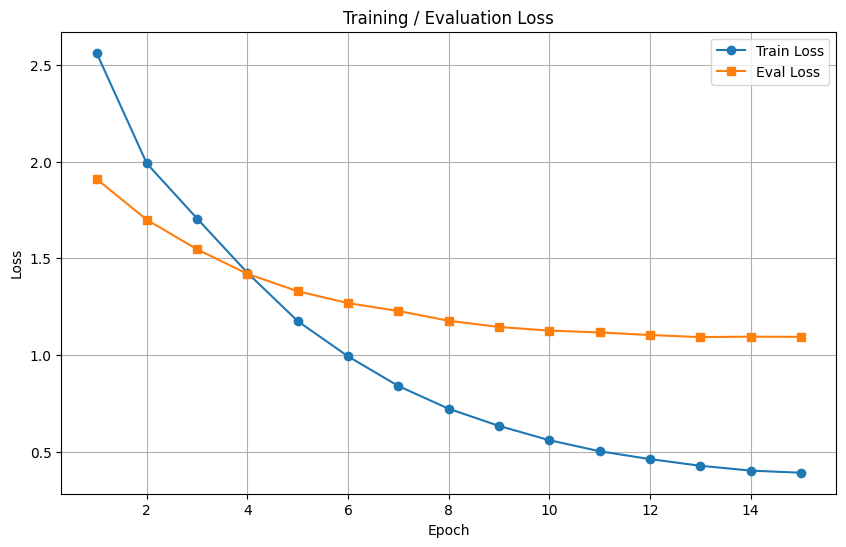

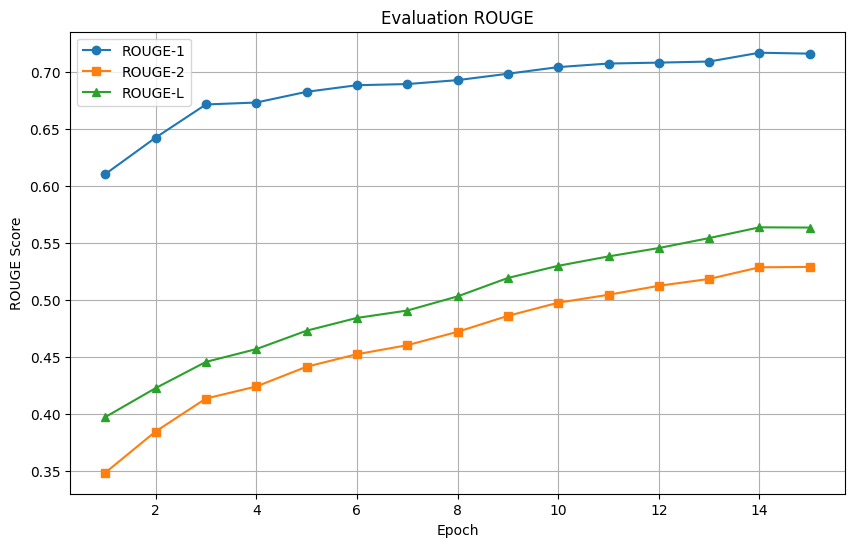

In [12]:
epochs = history["epoch"]

# Biểu đồ Loss
plt.figure(figsize=(10, 6))
plt.plot(epochs, history["train_loss"], label="Train Loss", marker="o")
plt.plot(epochs, history["eval_loss"], label="Eval Loss", marker="s")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training / Evaluation Loss")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve.png"), dpi=150)
plt.show()

# Biểu đồ ROUGE
plt.figure(figsize=(10, 6))
plt.plot(epochs, history["rouge1"], label="ROUGE-1", marker="o")
plt.plot(epochs, history["rouge2"], label="ROUGE-2", marker="s")
plt.plot(epochs, history["rougeL"], label="ROUGE-L", marker="^")
plt.xlabel("Epoch")
plt.ylabel("ROUGE Score")
plt.title("Evaluation ROUGE")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(OUTPUT_DIR, "rouge_curve.png"), dpi=150)
plt.show()


In [13]:
def summarize(text, model, tokenizer, max_length=128):
    """Tóm tắt văn bản bất kỳ."""
    segmented = word_segment(text)
    inputs = tokenizer(
        segmented, max_length=MAX_ARTICLE_LEN, truncation=True, return_tensors="pt"
    )
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_length=max_length,
            min_length=20,
            num_beams=NUM_BEAMS,
            early_stopping=True,
            no_repeat_ngram_size=3,
        )
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Load best model để demo
best_path = os.path.join(OUTPUT_DIR, "best_model")
if os.path.exists(best_path):
    print("\n🔍 DEMO TÓM TẮT:")
    demo_model = MBartForConditionalGeneration.from_pretrained(best_path).to(DEVICE)
    demo_model.eval()
    demo_tokenizer = AutoTokenizer.from_pretrained(best_path)

    # Test với 1 mẫu validation
    if valid_data:
        sample = valid_data[0]
        print(f"Bài gốc: {sample['article'][:500]}...")
        print(f"Tóm tắt gốc: {sample['summary']}")
        print(f"Tóm tắt model: {summarize(sample['article'], demo_model, demo_tokenizer)}")

print("\n✅ HOÀN THÀNH!")
print(f"📁 Best model: {os.path.join(OUTPUT_DIR, 'best_model')}")
print(f"📁 Final model: {final_model_path}")



🔍 DEMO TÓM TẮT:


Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

Bài gốc: Theo kế_hoạch đầu_tư phát_triển hệ_thống cây_xanh , công_viên , vườn hoa , hồ nước thành_phố Hà_Nội giai_đoạn từ năm 2013 - 2015 , cùng_với việc chặt hạ , dịch_chuyển , thay_thế 6.700 cây_xanh , thành_phố còn chi 1,3 tỷ đồng để đánh_mã_số 44.225 cây . Ngoài_ra , ngân_sách thành_phố cũng dành 35 tỷ đồng cho việc cắt tỉa cây_xanh trên các tuyến phố . Cây xà_cừ ngả vào nhà dân trên phố Lý_Nam_Đế ( Hà_Nội ) . Cụ_thể , các cơ_quan_chức_năng sẽ thực_hiện cắt sửa nhẹ_tán , cân_tán , khống_chế chiều cao...
Tóm tắt gốc: Kinh_phí cắt tỉa cây_xanh theo đơn công_văn , phòng_bão , hạ_độ cao , cắt cân_tán trên địa_bàn thành_phố Hà_Nội lên đến 35 tỷ đồng , trong đó chi_phí việc cắt tỉa cây xà_cừ 30 tỷ .
Tóm tắt model: Từ 2013 - 2015 , Hà_Nội đã chi 1,3 tỷ đồng để đánh_mã_số 44.225 cây và 35 tỷ đồng cho cắt tỉa cây_xanh . Kế_hoạch bao_gồm cắt tỉa 10.854 cây , bao_gồm xà_cừ và muồng . Chi_phí cắt tỉa xà_cừ là 30 tỷ đồng , trong khi cây cao , nguy_hiểm 5 tỷ đồng . Số_lượng cây xà_cừ không thay_